This file is for analyzing the EHT data. All analysis is finished and saved in the folder. If you want to rerun the analysis, please set RERUN_ANALYSIS = True.


What is needed:

-   `result/230_{day}.pkl` image of different hyperparam combinations


What is generated:

-   `{day}_all_data_mean.npy` averaged IQU of all combinations
-   `{day}_all_data.npy` IQU of all combinations
-   `{day}.npz` theta_mean,theta_std,P_mean...
-   `{day}_EVPA_1d.npy` evpa,q,u of all combinations
-   `{day}_1d.npz` 1d theta_mean,theta_std,P_mean...


In [1]:
RERUN_ANALYSIS = False

In [2]:
RERUN_ANALYSIS = True

In [3]:
import pickle
import numpy as np
import scipy.stats as stats
import os
from copy import deepcopy
from scipy import optimize
import scipy
import matplotlib.pyplot as plt
import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from utils.libanaly import Plot_Background, plot_quivers, CircleCalc

below are some functions.


In [4]:
def get_reloc_offset(dataimage):
    """
    This function receives a dataimage and returns the offset of the center of the image, so that you can relocate the blackhole to the center.
    """

    shape = dataimage.shape[0]
    xgrid = np.linspace(-16.3434, 16.3434, shape, endpoint=False)
    ygrid = np.linspace(-16.3434, 16.3434, shape, endpoint=False)
    diff = np.diff(xgrid)[0] / 2.0
    xgrid += diff
    ygrid += diff
    xmesh, ymesh = np.meshgrid(xgrid, ygrid, indexing="ij")

    iI = scipy.interpolate.RectBivariateSpline(
        xmesh[:, 0], ymesh[0, :], dataimage[:, :, 0]
    )

    Rres = 10
    Rmax = 10
    Rmin = 0.2

    Pres = 10
    Pmax = 1 * 2 * np.pi
    Pmin = 1.0 / 360.0 * 2 * np.pi

    dr = Rmin / Rres
    dphi = Pmin / Pres

    r = np.arange(np.round(Rmax / Rmin) * Rres + 1) * dr
    phi = (np.arange(np.round(Pmax / Pmin) * Pres + 1) - Pres / 2) * dphi

    window = np.ones((Rres + 1, Pres + 1))
    window[0, :] *= 0.5
    window[-1, :] *= 0.5
    window[:, 0] *= 0.5
    window[:, -1] *= 0.5

    window0 = np.ones(Pres + 1)
    window0[0] *= 0.5
    window0[-1] *= 0.5

    r_pk = np.zeros((17 * 17, len(phi)))
    r_pk_bar = np.zeros((17 * 17))
    sigma_r_bar = np.zeros((17 * 17))
    starting = int(shape / 2 - 8)

    for x0 in range(17):
        for y0 in range(17):
            x_mesh = r[:, None] * np.cos(phi[None, :]) + xmesh[:, 0][x0 + starting]
            y_mesh = r[:, None] * np.sin(phi[None, :]) + ymesh[0, :][y0 + starting]
            Ii = iI.ev(x_mesh, y_mesh)
            r_pk[x0 * 17 + y0] = np.argmax(Ii, axis=0)
            r_pk_bar[x0 * 17 + y0] = np.mean(r_pk[x0 * 17 + y0])
            sigma_r_bar[x0 * 17 + y0] = np.std(r_pk[x0 * 17 + y0])
    central = np.argmin(sigma_r_bar / r_pk_bar)
    xoff = int(central // 17 + starting - shape / 2 - 1)
    yoff = int(central % 17 + starting - shape / 2 - 1)

    return xoff, yoff

In [5]:
def gaussian(x, *param):
    mean = param[0]
    sigma = param[1]
    amplitude = param[2]
    return (
        amplitude
        / np.sqrt(2.0 * np.pi * sigma * sigma)
        * np.exp(-np.power(x - mean, 2.0) / 2.0 / sigma / sigma)
    )


def normalize_evpa(evpaarr):
    return ((evpaarr + 0.5 * np.pi) % np.pi) - 0.5 * np.pi


def vonmises_mean(d1evpaarr):
    # d1evpaarr is from -0.5pi to 0.5pi
    kappa_fit, mu_fit, _ = stats.vonmises.fit(d1evpaarr * 2)
    return mu_fit / 2


# def fit_gaussian2(d1evpaarr, bins_i):
#     counts, bins = np.histogram(d1evpaarr, bins=10 * bins_i)  # 10*(4)
#     # counts,bins =re_loc(counts,bins)
#     xarray = np.array([(bins[i] + bins[i + 1]) / 2 for i in range(len(bins) - 1)])
#     popt, pcov = optimize.curve_fit(
#         gaussian,
#         xarray,
#         counts,
#         p0=[xarray[np.argmax(counts)], 5, d1evpaarr.shape[0]],
#         maxfev=500000,
#         gtol=1e-10,
#     )
#     if abs(pcov[0][0]) > abs(popt[0]) or abs(pcov[1][1]) > abs(popt[1]):
#         print(f"badfit")
#         return np.array([np.nan, np.nan, np.nan])
#     else:
#         return popt


##########################################################################################
# These functions are not used in the code, if you are interested in them, try it :) #####
##########################################################################################


def fit_gaussian_calc(d1evpaarr):
    # d1evpaarr is from -0.5pi to 0.5pi
    kappa_fit, mu_fit, _ = stats.vonmises.fit(d1evpaarr * 2)
    sigma = np.sqrt(1 / kappa_fit) / 2
    mu_fit = mu_fit / 2
    t = deepcopy(d1evpaarr)
    t[t < -0.5 * np.pi + mu_fit] += np.pi
    t[t > 0.5 * np.pi + mu_fit] -= np.pi
    # use stats.norm.fit
    mu_fit, sigma_fit = stats.norm.fit(t)
    return np.array([mu_fit, sigma_fit])


def fit_vonmise(d1evpaarr):
    # d1evpaarr is from -0.5pi to pi
    kappa_fit, mu_fit, _ = stats.vonmises.fit(d1evpaarr * 2)
    sigma = np.sqrt(1 / kappa_fit) / 2
    mu_fit = mu_fit / 2
    t = deepcopy(d1evpaarr)
    t[t < -0.5 * np.pi + mu_fit] += np.pi
    t[t > 0.5 * np.pi + mu_fit] -= np.pi
    s, p = stats.kstest(t, "norm", args=(mu_fit, sigma))
    if p > 0.001 or True:
        return np.array([mu_fit, sigma])
    else:
        print(f"badfit,p={p},mu={mu_fit},sigma={sigma}")
        return np.array([np.nan, np.nan])

2D EHT Image: relocate images and Fit it


In [6]:
from utils.libanaly import fit_gaussian2

In [7]:
def topset_rank(data_cor, data_std, condition_good, weight):
    sum_of_pixels = np.zeros(data_cor[0].shape[1])
    for i in range(4):
        rmnan_times = np.nan_to_num(data_cor[i] / data_std[i].reshape(4096, 1), nan=0)
        rmnan_weight = np.nan_to_num(weight[i].reshape(4096, 1), nan=0)
        sum_of_pixels += np.sum(
            ((rmnan_times)[np.where((condition_good).reshape(4096))]) ** 2
            * rmnan_weight[np.where((condition_good).reshape(4096))],
            axis=0,
        )
    return sum_of_pixels

In [8]:
from functools import cmp_to_key


def my_cmp(i, j, _tmp_data):
    a = _tmp_data[i]
    b = _tmp_data[j]
    compare_item = ["zbl", "prior_fwhm", "sys_noise", "MEM", "TV", "T2V", "l1"]
    for item in compare_item:
        if a[item] < b[item]:
            return -1
        elif a[item] > b[item]:
            return 1

In [9]:
with open(f"data_in/230_95.pkl", "rb") as file1:
    data95 = pickle.loads(file1.read())
with open(f"data_in/230_96.pkl", "rb") as file1:
    data96 = pickle.loads(file1.read())
with open(f"data_in/230_100.pkl", "rb") as file1:
    data100 = pickle.loads(file1.read())
with open(f"data_in/230_101.pkl", "rb") as file1:
    data101 = pickle.loads(file1.read())

In [10]:
all_topset_data = []
# 用索引进行排序
order = sorted(
    range(len(data95["meta_data"])),
    key=cmp_to_key(lambda i, j: my_cmp(i, j, data95["meta_data"])),
)
data95_sorted = {}
for key in data95.keys():
    if key == "meta_data":
        data95_sorted[key] = [data95[key][i] for i in order]
    else:
        data95_sorted[key] = np.asarray(
            [data95[key][:, :, i] for i in order]
        ).transpose(1, 2, 0)

order = sorted(
    range(len(data96["meta_data"])),
    key=cmp_to_key(lambda i, j: my_cmp(i, j, data96["meta_data"])),
)
data96_sorted = {}
for key in data96.keys():
    if key == "meta_data":
        data96_sorted[key] = [data96[key][i] for i in order]
    else:
        data96_sorted[key] = np.asarray(
            [data96[key][:, :, i] for i in order]
        ).transpose(1, 2, 0)
order = sorted(
    range(len(data100["meta_data"])),
    key=cmp_to_key(lambda i, j: my_cmp(i, j, data100["meta_data"])),
)
data100_sorted = {}
for key in data100.keys():
    if key == "meta_data":
        data100_sorted[key] = [data100[key][i] for i in order]
    else:
        data100_sorted[key] = np.asarray(
            [data100[key][:, :, i] for i in order]
        ).transpose(1, 2, 0)
order = sorted(
    range(len(data101["meta_data"])),
    key=cmp_to_key(lambda i, j: my_cmp(i, j, data101["meta_data"])),
)
data101_sorted = {}
for key in data101.keys():
    if key == "meta_data":
        data101_sorted[key] = [data101[key][i] for i in order]
    else:
        data101_sorted[key] = np.asarray(
            [data101[key][:, :, i] for i in order]
        ).transpose(1, 2, 0)
all_topset_data.append(data95_sorted)
all_topset_data.append(data96_sorted)
all_topset_data.append(data100_sorted)
all_topset_data.append(data101_sorted)

In [11]:
rg_per_pixel = 0.51073125
conditiongt2 = np.array(
    [
        [
            2 <= np.sqrt((i - 31.5) ** 2 + (j - 31.5) ** 2) * rg_per_pixel
            for j in range(64)
        ]
        for i in range(64)
    ]
)

In [12]:
# offset_day is the result of get_reloc_offset function. If you think this block is time wasing, please set USING_CALCED_OFFSET = True and directly use the offset_day value.
USING_CALCED_OFFSET = True
offset_day = {95: (2, 0), 96: (1, 1), 100: (-4, 4), 101: (-1, 1)}

condition = np.ones((64, 64), dtype=bool)
data_cor_list = []
data_std_list = []
I_list = []

len_top = 4800
for day in [95, 96, 100, 101] if RERUN_ANALYSIS else []:
    print(day)
    # with open(f"data_in/230_{day}.pkl", "rb") as file1:
    #     data = pickle.loads(file1.read())
    # chi2averhist = [pic["chi2"] for pic in data["meta_data"]]
    # data["meta_data"].sort(key=lambda k: (k.get("chi2", 0)))
    # chi2aver = deepcopy(data["meta_data"])

    data = all_topset_data[[95, 96, 100, 101].index(day)]

    theta_mean = np.zeros((64, 64))
    theta_std = np.zeros((64, 64))
    theta_all = np.zeros((64, 64))
    theta_data = np.zeros((len_top, 64, 64))
    I_data = np.zeros((len_top, 64, 64))
    Q_data = np.zeros((len_top, 64, 64))
    U_data = np.zeros((len_top, 64, 64))
    All_data = np.zeros((len_top, 64, 64, 4))

    All_data[:, :, :, 0] = np.transpose(data["I_data"][::-1][:, :, :len_top], (2, 0, 1))
    All_data[:, :, :, 1] = np.transpose(data["Q_data"][::-1][:, :, :len_top], (2, 0, 1))
    All_data[:, :, :, 2] = np.transpose(data["U_data"][::-1][:, :, :len_top], (2, 0, 1))
    # These rotations are used to make the data in the same direction as the GRMHD data.
    # If you use our Plot_Background function, the matrix after rotate will output the correct image.
    All_data[:, :, :, 0] = np.rot90(All_data[:, :, :, 0], k=-1, axes=(1, 2))
    All_data[:, :, :, 1] = -np.rot90(All_data[:, :, :, 1], k=-1, axes=(1, 2))
    All_data[:, :, :, 2] = -np.rot90(All_data[:, :, :, 2], k=-1, axes=(1, 2))
    theta_data = 0.5 * np.arctan2(All_data[:, :, :, 2], All_data[:, :, :, 1])  # rad
    # move theta data to put vonmises mean at the center of theta range, that helps gaussian fit
    theta_vonmises_mean = np.apply_along_axis(vonmises_mean, 0, theta_data)
    theta_data = (
        CircleCalc.circle_sub_evpa(theta_data, theta_vonmises_mean)
        + theta_vonmises_mean
    )

    for bins in [
        100
    ]:  # ,6,4,14]: # bins=100 gives the best fit result (will get the most good fit points)
        res_arr = np.apply_along_axis(
            fit_gaussian2,
            0,
            theta_data,
            plot_failed=False,
            angle=True,
            lower_bound=-np.pi / 2,
            upper_bound=np.pi / 2,
            bins=bins,
            threshold=0.2,
        )
        theta_mean = res_arr[0, :, :]
        # although theta_vonmises_mean is (-0.5pi, 0.5pi), the theta_mean may be out of this range, so we need to normalize it to (-0.5pi, 0.5pi).
        theta_mean = normalize_evpa(theta_mean)
        theta_std = np.abs(res_arr[1, :, :])

    All_data_mean = np.mean(All_data, axis=0)
    if USING_CALCED_OFFSET:
        xoff, yoff = offset_day[day]
    else:
        xoff, yoff = get_reloc_offset(All_data_mean)
    print(f"xoff:{xoff},yoff:{yoff}")

    # This part relocates theta_mean, theta_std, All_data_mean and All_data, moves the blackhole to the center of the image.
    bigset = np.full((2, 64 + 16, 64 + 16), np.nan)
    bigset2 = np.full((64 + 16, 64 + 16, 4), np.nan)
    bigset3 = np.full((len_top, 64 + 16, 64 + 16, 4), np.nan)

    bigset[0, 9 : 64 + 9, 9 : 64 + 9] = theta_mean
    bigset[1, 9 : 64 + 9, 9 : 64 + 9] = theta_std
    bigset2[9 : 64 + 9, 9 : 64 + 9] = All_data_mean
    bigset3[:, 9 : 64 + 9, 9 : 64 + 9] = All_data

    theta_mean[:] = bigset[0, 9 + xoff : 64 + 9 + xoff, 9 + yoff : 64 + 9 + yoff]
    theta_std[:] = bigset[1, 9 + xoff : 64 + 9 + xoff, 9 + yoff : 64 + 9 + yoff]
    All_data_mean[:] = bigset2[9 + xoff : 64 + 9 + xoff, 9 + yoff : 64 + 9 + yoff]
    All_data[:] = bigset3[:, 9 + xoff : 64 + 9 + xoff, 9 + yoff : 64 + 9 + yoff]

    P_mean = np.sqrt(All_data_mean[:, :, 1] ** 2 + All_data_mean[:, :, 2] ** 2)
    condition = condition * (
        All_data_mean[:, :, 0] > np.nanmax(All_data_mean[:, :, 0]) * 0.1
    )
    condition = condition * np.isfinite(All_data_mean[:, :, 0]) * np.isfinite(theta_std)

    I_list.append(All_data_mean[:, :, 0])
    data_std_list.append(theta_std)
    data_cor_list.append(
        CircleCalc.circle_sub_evpa(theta_data, theta_mean)
        .transpose(1, 2, 0)
        .reshape(4096, len_top)
    )


condition[:, 0:5] = 0
condition[48:55, 10:19] = 0
condition = condition * conditiongt2
# np.save("data_out/condition", condition)

95
xoff:2,yoff:0
96
xoff:1,yoff:1
100
xoff:-4,yoff:4
101
xoff:-1,yoff:1


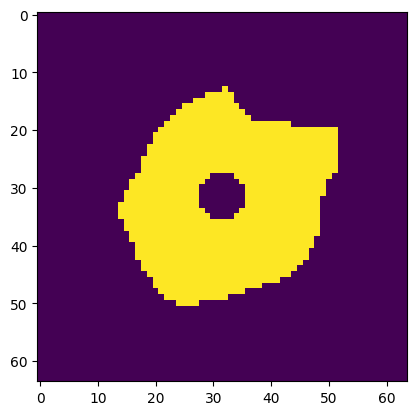

In [13]:
plt.imshow(condition)

In [14]:
sum_of_pixels = topset_rank(
    data_cor_list, data_std_list, condition, np.ones((4, 64, 64))
)

In [16]:
# offset_day is the result of get_reloc_offset function. If you think this block is time wasing, please set USING_CALCED_OFFSET = True and directly use the offset_day value.
USING_CALCED_OFFSET = True
offset_day = {95: (1, 0), 96: (0, 1), 100: (-1, 2), 101: (0, 0)}

condition = np.ones((64, 64), dtype=bool)

len_top = 1572
for day in [95, 96, 100, 101] if RERUN_ANALYSIS else []:
    print(day)
    # with open(f"data_in/230_{day}.pkl", "rb") as file1:
    #     data = pickle.loads(file1.read())
    # chi2averhist = [pic["chi2"] for pic in data["meta_data"]]
    # data["meta_data"].sort(key=lambda k: (k.get("chi2", 0)))
    # chi2aver = deepcopy(data["meta_data"])

    data = all_topset_data[[95, 96, 100, 101].index(day)]

    theta_mean = np.zeros((64, 64))
    theta_std = np.zeros((64, 64))
    theta_all = np.zeros((64, 64))
    theta_data = np.zeros((len_top, 64, 64))
    I_data = np.zeros((len_top, 64, 64))
    Q_data = np.zeros((len_top, 64, 64))
    U_data = np.zeros((len_top, 64, 64))
    All_data = np.zeros((len_top, 64, 64, 4))

    All_data[:, :, :, 0] = np.transpose(
        data["I_data"][::-1][:, :, sum_of_pixels.argsort()[:len_top]], (2, 0, 1)
    )
    All_data[:, :, :, 1] = np.transpose(
        data["Q_data"][::-1][:, :, sum_of_pixels.argsort()[:len_top]], (2, 0, 1)
    )
    All_data[:, :, :, 2] = np.transpose(
        data["U_data"][::-1][:, :, sum_of_pixels.argsort()[:len_top]], (2, 0, 1)
    )
    # These rotations are used to make the data in the same direction as the GRMHD data.
    # If you use our Plot_Background function, the matrix after rotate will output the correct image.
    All_data[:, :, :, 0] = np.rot90(All_data[:, :, :, 0], k=-1, axes=(1, 2))
    All_data[:, :, :, 1] = -np.rot90(All_data[:, :, :, 1], k=-1, axes=(1, 2))
    All_data[:, :, :, 2] = -np.rot90(All_data[:, :, :, 2], k=-1, axes=(1, 2))
    theta_data = 0.5 * np.arctan2(All_data[:, :, :, 2], All_data[:, :, :, 1])  # rad
    # move theta data to put vonmises mean at the center of theta range, that helps gaussian fit
    theta_vonmises_mean = np.apply_along_axis(vonmises_mean, 0, theta_data)
    theta_data = (
        CircleCalc.circle_sub_evpa(theta_data, theta_vonmises_mean)
        + theta_vonmises_mean
    )

    for bins in [
        100
    ]:  # ,6,4,14]: # bins=100 gives the best fit result (will get the most good fit points)
        res_arr = np.apply_along_axis(
            fit_gaussian2,
            0,
            theta_data,
            plot_failed=False,
            angle=True,
            lower_bound=-np.pi / 2,
            upper_bound=np.pi / 2,
            bins=bins,
            threshold=0.2,
        )
        theta_mean = res_arr[0, :, :]
        # although theta_vonmises_mean is (-0.5pi, 0.5pi), the theta_mean may be out of this range, so we need to normalize it to (-0.5pi, 0.5pi).
        theta_mean = normalize_evpa(theta_mean)
        theta_std = np.abs(res_arr[1, :, :])

    All_data_mean = np.mean(All_data, axis=0)
    if USING_CALCED_OFFSET:
        xoff, yoff = offset_day[day]
    else:
        xoff, yoff = get_reloc_offset(All_data_mean)
    print(f"xoff:{xoff},yoff:{yoff}")

    # This part relocates theta_mean, theta_std, All_data_mean and All_data, moves the blackhole to the center of the image.
    bigset = np.full((2, 64 + 16, 64 + 16), np.nan)
    bigset2 = np.full((64 + 16, 64 + 16, 4), np.nan)
    bigset3 = np.full((len_top, 64 + 16, 64 + 16, 4), np.nan)

    bigset[0, 9 : 64 + 9, 9 : 64 + 9] = theta_mean
    bigset[1, 9 : 64 + 9, 9 : 64 + 9] = theta_std
    bigset2[9 : 64 + 9, 9 : 64 + 9] = All_data_mean
    bigset3[:, 9 : 64 + 9, 9 : 64 + 9] = All_data

    theta_mean[:] = bigset[0, 9 + xoff : 64 + 9 + xoff, 9 + yoff : 64 + 9 + yoff]
    theta_std[:] = bigset[1, 9 + xoff : 64 + 9 + xoff, 9 + yoff : 64 + 9 + yoff]
    All_data_mean[:] = bigset2[9 + xoff : 64 + 9 + xoff, 9 + yoff : 64 + 9 + yoff]
    All_data[:] = bigset3[:, 9 + xoff : 64 + 9 + xoff, 9 + yoff : 64 + 9 + yoff]

    np.save(f"data_out/{day}_all_data_mean", All_data_mean)
    np.save(f"data_out/{day}_all_data", All_data)

    P_mean = np.sqrt(All_data_mean[:, :, 1] ** 2 + All_data_mean[:, :, 2] ** 2)
    condition = condition * (
        All_data_mean[:, :, 0] > np.nanmax(All_data_mean[:, :, 0]) * 0.1
    )
    condition = condition * np.isfinite(All_data_mean[:, :, 0]) * np.isfinite(theta_std)
    np.savez(f"data_out/{day}", theta_mean, theta_std, P_mean, All_data_mean[:, :, 0])


condition[:, 0:5] = 0
condition[48:55, 10:19] = 0
condition = condition * conditiongt2
np.save("data_out/condition", condition)

95
xoff:1,yoff:0
96
xoff:0,yoff:1
100
xoff:-1,yoff:2
101
xoff:0,yoff:0


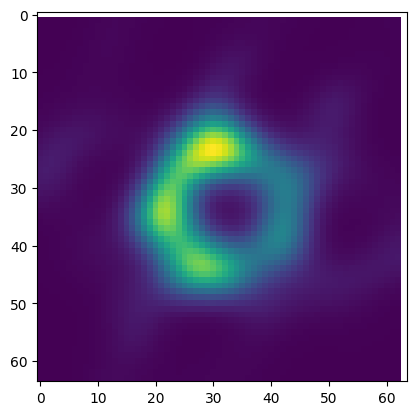

In [17]:
plt.imshow(All_data_mean[:, :, 0])

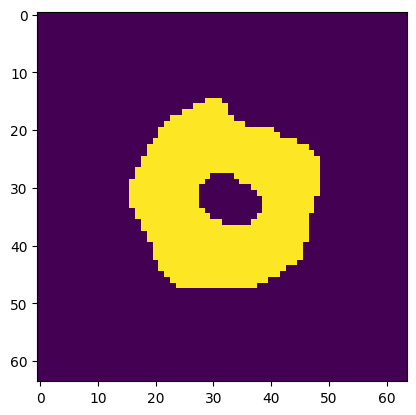

In [16]:
plt.imshow(condition)

In [31]:
data["meta_data"]

[{'zbl': 0.8,
  'prior_fwhm': 50.0,
  'sys_noise': 0.05,
  'MEM': 10.0,
  'TV': 0.0,
  'T2V': 0.0,
  'l1': 10.0,
  'm': 0.263556223377665,
  'pvis': 0.28673247333077556,
  'cphase': 0.10283822602117716,
  'logcamp': 0.2424936102122427,
  'vis': 0.4400264473544888,
  'chi2': 0.2617860945293029},
 {'zbl': 0.8,
  'prior_fwhm': 50.0,
  'sys_noise': 0.05,
  'MEM': 10.0,
  'TV': 0.0,
  'T2V': 0.0,
  'l1': 1.0,
  'm': 0.270610487987559,
  'pvis': 0.29708641213118403,
  'cphase': 0.10389499946258081,
  'logcamp': 0.24557062798307192,
  'vis': 0.43912087834029745,
  'chi2': 0.26286216859531675},
 {'zbl': 0.8,
  'prior_fwhm': 50.0,
  'sys_noise': 0.05,
  'MEM': 10.0,
  'TV': 0.0,
  'T2V': 0.0,
  'l1': 100.0,
  'm': 0.2526538912577442,
  'pvis': 0.2738071433905706,
  'cphase': 0.10447216821170022,
  'logcamp': 0.23896259105933715,
  'vis': 0.4497613890932117,
  'chi2': 0.26439871612141636},
 {'zbl': 0.8,
  'prior_fwhm': 50.0,
  'sys_noise': 0.05,
  'MEM': 10.0,
  'TV': 0.0,
  'T2V': 0.0,
  'l1': 

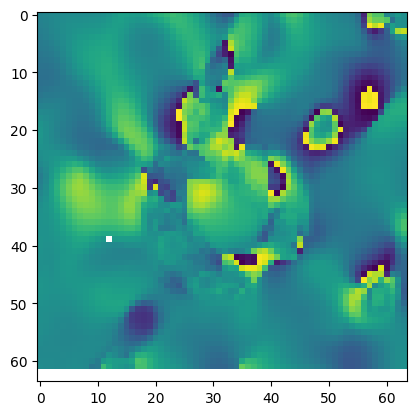

In [49]:
plt.imshow(data_cor_list[0][:, 1].reshape(64, 64))

In [17]:
def plt_hist(data, params, index=None):
    if index is not None:
        _data = [data[i] for i in index]
    else:
        _data = data
    params_value_list = [_data[i][params] for i in range(len(_data))]
    plt.hist(params_value_list)
    res = {}
    for i in _data:
        if i[params] in res:
            res[i[params]] += 1 / len(_data)
        else:
            res[i[params]] = 1 / len(_data)
    return res

In [76]:
all_topset_data[0]["meta_data"]

[{'zbl': 0.4,
  'prior_fwhm': 40.0,
  'sys_noise': 0.0,
  'MEM': 10.0,
  'TV': 0.0,
  'T2V': 0.0,
  'l1': 0.0,
  'm': 3.8907034379075704,
  'pvis': 4.005342629685619,
  'cphase': 0.5426340317384475,
  'logcamp': 0.8313581101686255,
  'vis': 2.1255534613591225,
  'chi2': 1.1665152010887319},
 {'zbl': 0.4,
  'prior_fwhm': 40.0,
  'sys_noise': 0.0,
  'MEM': 10.0,
  'TV': 0.0,
  'T2V': 0.0,
  'l1': 1.0,
  'm': 4.120803761893599,
  'pvis': 4.1971672178162445,
  'cphase': 0.5271128881172147,
  'logcamp': 0.8852915086165511,
  'vis': 2.1086009043235374,
  'chi2': 1.1736684336857677},
 {'zbl': 0.4,
  'prior_fwhm': 40.0,
  'sys_noise': 0.0,
  'MEM': 10.0,
  'TV': 0.0,
  'T2V': 0.0,
  'l1': 10.0,
  'm': 4.310986801419227,
  'pvis': 4.501237872322197,
  'cphase': 0.5621916082593212,
  'logcamp': 0.8887503728041611,
  'vis': 2.284172499600746,
  'chi2': 1.2450381602214093},
 {'zbl': 0.4,
  'prior_fwhm': 40.0,
  'sys_noise': 0.0,
  'MEM': 10.0,
  'TV': 0.0,
  'T2V': 0.0,
  'l1': 100.0,
  'm': 4.093

In [84]:
sum_of_pixels.argsort()

array([2254, 4149, 2306, ..., 4477, 4478, 4475])

In [19]:
sum_of_chi2 = np.zeros(4800)
for i in range(4800):
    sum_chi2 = 0
    for day in range(4):
        sum_chi2 += all_topset_data[day]["meta_data"][i]["chi2"]
    sum_of_chi2[i] = sum_chi2

In [20]:
sum_of_chi2[1]

np.float64(6.1006273733554215)

(array([  8.,  11.,  10.,   3.,   3.,   0.,   5.,   1.,   0.,   0.,   1.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   1.,   2.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   1.,   0.,   6.,   3.,  12.,  10.,
         12.,  10.,   9.,   5.,   9.,  18.,  19.,  26.,  30.,  30.,  51.,
         99., 165., 231., 236., 184., 123.,  80.,  55.,  38.,  28.,  25.,
         12.]),
 array([-1.57054247e+00, -1.53913141e+00, -1.50772034e+00, -1.47630927e+00,
        -1.44489820e+00, -1.41348714e+00, -1.38207607e+00, -1.35066500e+00,
        -1.31925393e+00, -1.28784287e+00, -1.25643180e+00, -1.22502073e+00,
        -1.19360966e+00, -1.16219860e+00, -1.13078753e+00, -1.09937646e+00,
        -1.067

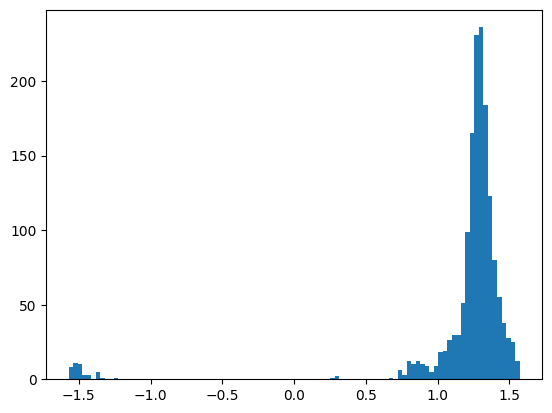

In [50]:
plt.hist(
    (0.5 * np.arctan2(all_topset_data[0]["Q_data"], all_topset_data[0]["U_data"]))[
        20, 40
    ][sum_of_pixels.argsort()[:1572]],
    bins=100,
)

{0.8: 0.3702290076335851, 0.7: 0.3136132315521609, 0.6: 0.21564885496183137, 0.5: 0.08651399491094161, 0.4: 0.013994910941475834}
{0.5: 0.1819338422391855, 0.8: 0.24618320610686914, 0.6: 0.2264631043256989, 0.7: 0.24300254452926104, 0.4: 0.10241730279898247}
{50.0: 0.5209923664122091, 40.0: 0.4790076335877822}
{50.0: 0.29898218829516365, 40.0: 0.7010178117048277}
{0.05: 0.4484732824427444, 0.02: 0.3072519083969447, 0.01: 0.17175572519083956, 0.0: 0.07251908396946566}
{0.02: 0.3155216284987258, 0.05: 0.2779898218829502, 0.01: 0.26145038167938806, 0.0: 0.1450381679389315}
{10.0: 0.6717557251908332, 100.0: 0.3282442748091582}
{100.0: 0.8511450381679301, 10.0: 0.14885496183206123}
{0.0: 0.3759541984732797, 1.0: 0.37086513994910675, 10.0: 0.253180661577607}
{0.0: 0.39567430025444994, 1.0: 0.37722646310432295, 10.0: 0.22709923664122053}
{0.0: 0.33333333333333115, 1.0: 0.3314249363867663, 10.0: 0.2875318066157745, 100.0: 0.047709923664122085}
{1.0: 0.3002544529262069, 0.0: 0.3008905852417285,

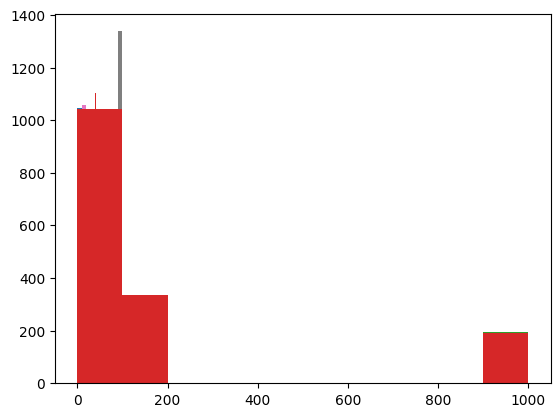

In [ ]:
for typ in ["zbl", "prior_fwhm", "sys_noise", "MEM", "TV", "T2V", "l1"]:
    print(plt_hist(all_topset_data[0]["meta_data"], typ, sum_of_chi2.argsort()[:1572]))
    print(
        plt_hist(all_topset_data[0]["meta_data"], typ, sum_of_pixels.argsort()[:1572])
    )

{0.5: 0.1819338422391855,
 0.8: 0.24618320610686914,
 0.6: 0.2264631043256989,
 0.7: 0.24300254452926104,
 0.4: 0.10241730279898247}

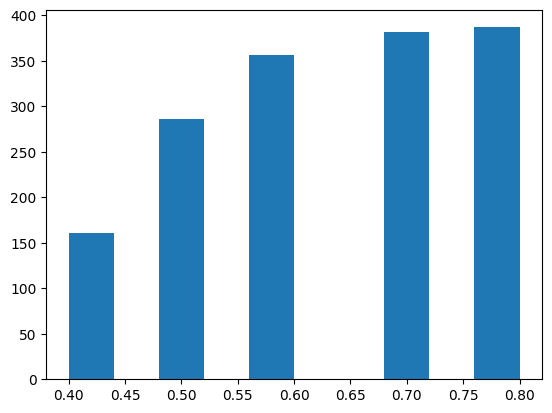

In [18]:
plt_hist(all_topset_data[0]["meta_data"], "zbl", sum_of_pixels.argsort()[:1572])

{0.8: 0.3702290076335851,
 0.7: 0.3136132315521609,
 0.6: 0.21564885496183137,
 0.5: 0.08651399491094161,
 0.4: 0.013994910941475834}

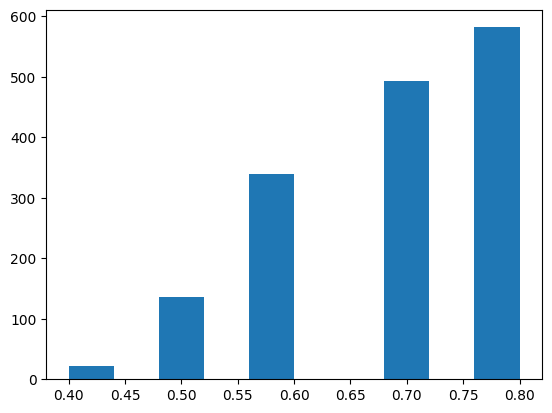

In [ ]:
plt_hist(all_topset_data[0]["meta_data"], "zbl", sum_of_chi2.argsort()[:1572])

{100.0: 0.8256997455470653, 10.0: 0.17430025445292605}

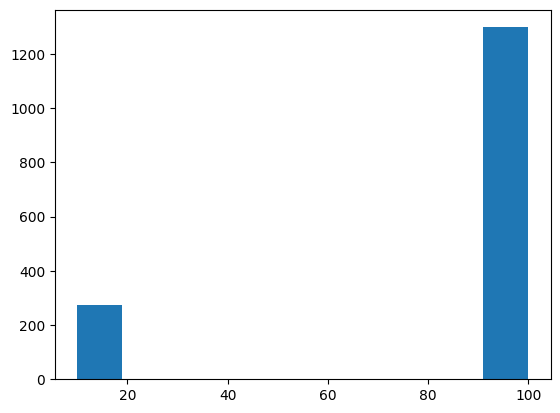

In [ ]:
plt_hist(all_topset_data[0]["meta_data"], "MEM", sum_of_pixels.argsort()[:1572])

{0.6: 0.22773536895674215,
 0.8: 0.21628498727735299,
 0.5: 0.19974554707379086,
 0.7: 0.2194656488549611,
 0.4: 0.13676844783715045}

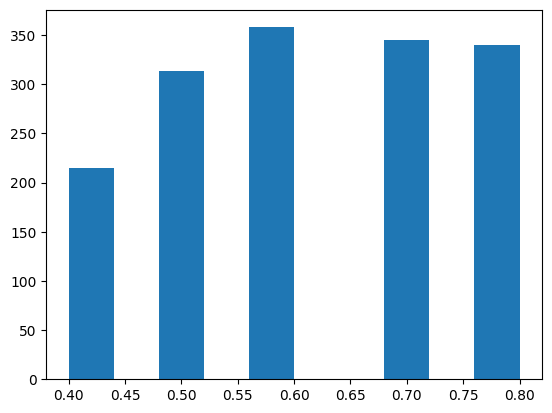

In [ ]:
plt_hist(all_topset_data[0]["meta_data"], "zbl", sum_of_pixels.argsort()[:1572])

1D EHT Image: calculate the 1D EVPA (Integrate the radius), and Fit it


In [37]:
def Create_EVPA_Dataset(image1):
    """
    This Function calculates 1D EVPA from 2D image.
    """

    xgrid = np.linspace(-16.3434, 16.3434, 64, endpoint=False)
    ygrid = np.linspace(-16.3434, 16.3434, 64, endpoint=False)
    diff = np.diff(xgrid)[0] / 2.0
    xgrid += diff
    ygrid += diff
    xmesh, ymesh = np.meshgrid(xgrid, ygrid, indexing="ij")

    iQ = scipy.interpolate.RectBivariateSpline(
        xmesh[:, 0], ymesh[0, :], image1[:, :, 1]
    )
    iU = scipy.interpolate.RectBivariateSpline(
        xmesh[:, 0], ymesh[0, :], image1[:, :, 2]
    )
    iI = scipy.interpolate.RectBivariateSpline(
        xmesh[:, 0], ymesh[0, :], image1[:, :, 0]
    )

    Rres = 10
    Rmax = 16.343
    Rmin = 0.2

    Pres = 10
    Pmax = 1 * 2 * np.pi
    Pmin = 1.0 / 360.0 * 2 * np.pi

    dr = Rmin / Rres
    dphi = Pmin / Pres

    r = np.arange(np.round(Rmax / Rmin) * Rres + 1) * dr
    phi = (np.arange(np.round(Pmax / Pmin) * Pres + 1) - Pres / 2) * dphi

    window = np.ones((Rres + 1, Pres + 1))
    window[0, :] *= 0.5
    window[-1, :] *= 0.5
    window[:, 0] *= 0.5
    window[:, -1] *= 0.5

    window0 = np.ones(Pres + 1)
    window0[0] *= 0.5
    window0[-1] *= 0.5

    x_mesh = r[:, None] * np.cos(phi[None, :])
    y_mesh = r[:, None] * np.sin(phi[None, :])

    Ii = iI.ev(x_mesh, y_mesh)
    Qi = iQ.ev(x_mesh, y_mesh)
    Ui = iU.ev(x_mesh, y_mesh)

    integrand_Q = r[:, None] * Qi * Ii * dr * dphi
    integrand_U = r[:, None] * Ui * Ii * dr * dphi

    # fast integration, for each point there are 6*6 blocks to be integrated, the border overlaps.
    # fast?
    Rn = round(Rmax / Rmin)
    Pn = round(Pmax / Pmin)

    integrated_Q_phi = np.array(
        [
            (integrand_Q[:, Pres * j : Pres * (j + 1) + 1] * window0).sum()
            for j in range(Pn)
        ]
    )
    integrated_U_phi = np.array(
        [
            (integrand_U[:, Pres * j : Pres * (j + 1) + 1] * window0).sum()
            for j in range(Pn)
        ]
    )

    integrated_Q_phi_10deg = np.array(
        [
            np.sum([integrated_Q_phi[(i + k - 1) % Pn] for k in range(3)])
            for i in range(Pn)
        ]
    )
    integrated_U_phi_10deg = np.array(
        [
            np.sum([integrated_U_phi[(i + k - 1) % Pn] for k in range(3)])
            for i in range(Pn)
        ]
    )

    evpa_phi_10deg = (
        (180.0 / np.pi)
        * 0.5
        * np.arctan2(integrated_U_phi_10deg, integrated_Q_phi_10deg)
    )
    return evpa_phi_10deg, integrated_Q_phi_10deg, integrated_U_phi_10deg

In [38]:
from utils.libanaly import ImageS

In [ ]:
for day in [95, 96, 100, 101] if RERUN_ANALYSIS else []:
    print(day)
    All_data = np.load(f"data_out/{day}_all_data.npy")
    EVPA_1d = np.zeros((All_data.shape[0], 360))
    for i in range(All_data.shape[0]):
        print(i)
        EVPA_1d[i] = (
            ImageS(
                All_data[i],
                rotation_angle=0,
                gaussian_kernel=0,
                init_fov=32.6868,
            ).evpa_phi_10deg
            / 180
            * np.pi
        )
        EVPA_1d[i] = np.roll(
            EVPA_1d[i], -90
        )  # rad 从pcolormesh显示的顶端（y轴正向）逆时针算起的
    np.save(f"data_out/{day}_EVPA_1d", EVPA_1d)

95
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
260
261
262
263
264
265
266
267
268
269
270
271
272
273
274
275
276

In [39]:
for day in [95, 96, 100, 101] if RERUN_ANALYSIS else []:
    print(day)
    EVPA_1d = np.load(f"data_out/{day}_EVPA_1d.npy")
    EVPA_vonmises_mean = np.apply_along_axis(vonmises_mean, 0, EVPA_1d)
    EVPA_1d = (
        CircleCalc.circle_sub_evpa(EVPA_1d, EVPA_vonmises_mean) + EVPA_vonmises_mean
    )

    for bins in [100]:
        res_arr = np.apply_along_axis(
            fit_gaussian2,
            0,
            EVPA_1d,
            plot_failed=False,
            angle=True,
            lower_bound=-np.pi / 2,
            upper_bound=np.pi / 2,
            bins=bins,
            threshold=0.2,
        )
        theta_mean = res_arr[0]
        theta_mean = normalize_evpa(theta_mean)
        theta_std = np.abs(res_arr[1])
        np.savez(f"data_out/{day}_1d", theta_mean, theta_std)

95


96
100
101
